In [ ]:
import sys
print(sys.executable)


c:\Users\Ghaith\AppData\Local\Programs\Python\Python311\python.exe


In [8]:
import os
import sys
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import xy

print("rasterio", rasterio.__version__)
print("numpy", np.__version__)
print("pandas", pd.__version__)

rasterio 1.4.4
numpy 2.4.4
pandas 3.0.2


 Définit les chemins, les fichiers sources et les constantes globales du pipeline (dossiers, rasters de crue, 11 facteurs, 10 000 points/classe, seed 42)

In [9]:
DATA_DIR = "data/raw"
OUT_DIR  = "data/processed"
OUT_CSV  = os.path.join(OUT_DIR, "training_data_kosi.csv")

FLOOD_CANDIDATES = [
    "composite_flood_dualpol.tif",
    "composite_flood_otsu.tif",
]

FACTORS = [
    "DEM.tif", "Slope.tif", "Aspect.tif", "Curvature.tif",
    "TRI.tif", "TWI.tif", "NDVI.tif", "NDBI.tif",
    "DD.tif", "DR.tif", "GFI.tif",
]

N_POINTS_PER_CLASS = 10_000
RANDOM_SEED = 42

os.makedirs(OUT_DIR, exist_ok=True)
print("Dossier de sortie :", OUT_DIR)

Dossier de sortie : data/processed


Recherche le raster de crue (avec fallback automatique) et vérifie la présence des 11 facteurs sur disque avant toute extraction

In [10]:
def find_flood_raster(data_dir):
    for name in FLOOD_CANDIDATES:
        p = os.path.join(data_dir, name)
        if os.path.exists(p):
            return p
    cands = [f for f in os.listdir(data_dir)
             if f.lower().endswith(".tif") and "flood" in f.lower()]
    if len(cands) == 1:
        return os.path.join(data_dir, cands[0])
    raise FileNotFoundError(f"Raster de crue introuvable. Contenu : {os.listdir(data_dir)}")

flood_path = find_flood_raster(DATA_DIR)
print("Raster de crue :", flood_path)

factor_paths = {}
for name in FACTORS:
    p = os.path.join(DATA_DIR, name)
    if os.path.exists(p):
        factor_paths[name.replace(".tif", "")] = p
    else:
        print(f"⚠️  Facteur manquant : {name}")

print(f"\n{len(factor_paths)} facteurs trouvés :")
for k in factor_paths:
    print("  -", k)

Raster de crue : data/raw\composite_flood_dualpol.tif

11 facteurs trouvés :
  - DEM
  - Slope
  - Aspect
  - Curvature
  - TRI
  - TWI
  - NDVI
  - NDBI
  - DD
  - DR
  - GFI


 S'assure que le raster de crue et les 11 facteurs partagent le même CRS et la même résolution.

In [ ]:
crs_list = []
for f in [flood_path] + list(factor_paths.values()):
    with rasterio.open(f) as src:
        print(f"  {os.path.basename(f):30s}  CRS={src.crs}  res={src.res}")
        crs_list.append(src.crs)

same_crs = all(c == crs_list[0] for c in crs_list)
print("\nTous les CRS identiques :", same_crs)
if not same_crs:
    print(" Reprojeter dans QGIS : Raster → Projections → Warp")

--- CRS / résolution ---
  composite_flood_dualpol.tif     CRS=EPSG:32645  res=(9.491512623745901, 9.491710435576165)
  DEM.tif                         CRS=EPSG:32645  res=(29.345024222175915, 29.34764797235855)
  Slope.tif                       CRS=EPSG:32645  res=(29.347168996297444, 29.3471689962975)
  Aspect.tif                      CRS=EPSG:32645  res=(29.347168996297455, 29.347168996297473)
  Curvature.tif                   CRS=EPSG:32645  res=(29.347168996297455, 29.347168996297473)
  TRI.tif                         CRS=EPSG:32645  res=(29.347168996297455, 29.348036126478167)
  TWI.tif                         CRS=EPSG:32645  res=(29.345024222175915, 29.342312036363577)
  NDVI.tif                        CRS=EPSG:32645  res=(9.999524761633731, 9.999524761633722)
  NDBI.tif                        CRS=EPSG:32645  res=(10.0, 10.0)
  DD.tif                          CRS=EPSG:32645  res=(562.1332840000018, 562.1332840000016)
  DR.tif                          CRS=EPSG:32645  res=(562.133

 Charge la bande cible et vérifie les valeurs uniques après nettoyage nodata.

In [20]:
with rasterio.open(flood_path) as src:
    flood_arr = src.read(1)
    flood_nodata = src.nodata
    flood_transform = src.transform
    flood_crs = src.crs

valid_flood = np.isfinite(flood_arr) if flood_arr.dtype.kind == "f" else np.ones_like(flood_arr, bool)
if flood_nodata is not None:
    valid_flood &= (flood_arr != flood_nodata)

uniq = np.unique(flood_arr[valid_flood])
print("Valeurs uniques :", uniq[:10])

Valeurs uniques : [  0   1 255]


Sélectionne aléatoirement jusqu'à 50 000 pixels par classe (inondé/sec) comme pool de travail avant extraction, afin de garantir un volume suffisant après nettoyage des NaN.

In [ ]:
POOL_PER_CLASS = 50_000  
TARGET_PER_CLASS = 10_000  

flooded = (flood_arr > 0) & valid_flood
dry = (flood_arr == 0) & valid_flood

r1, c1 = np.where(flooded)
r0, c0 = np.where(dry)
print(f"Pixels inondés disponibles     : {len(r1):,}")
print(f"Pixels non inondés disponibles : {len(r0):,}")

n1 = min(POOL_PER_CLASS, len(r1))
n0 = min(POOL_PER_CLASS, len(r0))
rng = np.random.default_rng(RANDOM_SEED)
i1 = rng.choice(len(r1), size=n1, replace=False)
i0 = rng.choice(len(r0), size=n0, replace=False)

rows = np.concatenate([r1[i1], r0[i0]])
cols = np.concatenate([c1[i1], c0[i0]])
pool_labels = np.concatenate([np.ones(n1, np.int8), np.zeros(n0, np.int8)])
print(f"Pool candidat : {len(rows):,} points ({n1:,} inondés / {n0:,} secs)")

Pixels inondés disponibles     : 8,999,767
Pixels non inondés disponibles : 243,867,224
Pool candidat : 100,000 points (50,000 inondés / 50,000 secs)


In [ ]:
xs, ys = xy(flood_transform, rows, cols)
pts = list(zip(xs, ys))
data = {}
for name, path in factor_paths.items():
    with rasterio.open(path) as src:
        if src.crs != flood_crs:
            print(f" {name}: CRS différent, ignoré")
            continue
        nodata = src.nodata
        vals = np.array([v[0] for v in src.sample(pts)], dtype=np.float32)
        if nodata is not None:
            vals[vals == nodata] = np.nan
        vals[~np.isfinite(vals)] = np.nan
        data[name] = vals
    print(f"  {name:10s} : {np.isnan(vals).sum():>6,} NaN / {len(vals):,}")

  DEM        :      0 NaN / 100,000
  Slope      :      0 NaN / 100,000
  Aspect     :      0 NaN / 100,000
  Curvature  : 48,514 NaN / 100,000
  TRI        : 47,375 NaN / 100,000
  TWI        :      0 NaN / 100,000
  NDVI       : 48,606 NaN / 100,000
  NDBI       : 48,621 NaN / 100,000
  DD         :      0 NaN / 100,000
  DR         :      0 NaN / 100,000
  GFI        :      0 NaN / 100,000


In [26]:
# 1) Construire le DataFrame du pool
pool_df = pd.DataFrame(data)

# --- Diagnostic : longueurs ---
print(f"len(pool_labels) = {len(pool_labels):,}")
print(f"pool_df rows     = {len(pool_df):,}")
print(f"pool_df columns  = {list(pool_df.columns)}")

# --- Ajouter 'label' si absent ---
if "label" not in pool_df.columns:
    if len(pool_labels) != len(pool_df):
        raise ValueError(
            f"Incohérence : pool_labels={len(pool_labels)} vs pool_df={len(pool_df)}"
        )
    pool_df.insert(0, "label", pool_labels)
    print("✅ Colonne 'label' ajoutée.")
else:
    print("ℹ️  Colonne 'label' déjà présente.")

# --- Vérification finale ---
assert "label" in pool_df.columns, "label absent après insert !"
print(f"\nAperçu :\n{pool_df.head()}")
print(f"\nDistribution du pool AVANT nettoyage :")
print(pool_df["label"].value_counts().sort_index())

# 2) Nettoyage : supprimer les NaN
n_before = len(pool_df)
pool_df = pool_df.dropna().reset_index(drop=True)
n_after = len(pool_df)
print(f"\nNettoyage : {n_before:,} → {n_after:,} lignes "
      f"(supprimé {n_before - n_after:,} NaN)")

# 3) Distribution après nettoyage
counts = pool_df["label"].value_counts().sort_index()
print(f"\nAprès nettoyage :")
print(f"  classe 0 (sec)    : {counts.get(0, 0):,}")
print(f"  classe 1 (inondé) : {counts.get(1, 0):,}")

# 4) Échantillonner EXACTEMENT TARGET_PER_CLASS par classe (sans groupby.apply)
n_final = min(TARGET_PER_CLASS, counts.get(0, 0), counts.get(1, 0))
if n_final < TARGET_PER_CLASS:
    print(f"\n⚠️  Pas assez de données propres → {n_final:,} par classe")
else:
    print(f"\n✅ Objectif atteint : {n_final:,} par classe")

sampled = []
for cls in [0, 1]:
    subset = pool_df[pool_df["label"] == cls]
    n = min(n_final, len(subset))
    sampled.append(subset.sample(n=n, random_state=RANDOM_SEED))
df = pd.concat(sampled, ignore_index=True)

# 5) Mélanger
df = df.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

print(f"\n✅ Échantillon final : {len(df):,} lignes")
print(df["label"].value_counts().sort_index())
print(f"\nShape : {df.shape}")
print(f"Colonnes : {list(df.columns)}")
df.head()

len(pool_labels) = 100,000
pool_df rows     = 100,000
pool_df columns  = ['DEM', 'Slope', 'Aspect', 'Curvature', 'TRI', 'TWI', 'NDVI', 'NDBI', 'DD', 'DR', 'GFI']
✅ Colonne 'label' ajoutée.

Aperçu :
   label   DEM     Slope     Aspect  Curvature       TRI        TWI      NDVI  \
0      1   0.0  0.000000   0.000000        NaN       NaN   0.000000       NaN   
1      1   0.0  0.000000   0.000000        NaN       NaN   0.000000       NaN   
2      1  37.0  0.000000  -1.000000       -0.0  0.000000  14.198975  0.337672   
3      1  31.0  4.210446  36.869896       -0.0  1.054093   7.228396  0.219877   
4      1   0.0  0.000000   0.000000        NaN       NaN   0.000000       NaN   

       NDBI        DD           DR   GFI  
0       NaN  0.167850     0.000000  0.00  
1       NaN  0.169371     0.000000  0.00  
2 -0.062608  0.414593  1589.953003  0.25  
3  0.002865  0.731883   562.133301  0.25  
4       NaN  0.096071     0.000000  0.00  

Distribution du pool AVANT nettoyage :
label
0    50000

,label,DEM,Slope,Aspect,Curvature,TRI,TWI,NDVI,NDBI,DD,DR,GFI
0,1,29.0,3.645159,186.340195,-0.464438,1.314684,7.163857,0.243169,0.046091,1.384207,562.133301,0.142857
1,0,36.0,1.316891,288.434937,0.116109,0.415740,10.286951,0.470822,-0.257311,0.819868,2317.734863,0.555556
2,0,40.0,0.640011,45.000000,-0.000000,0.314270,8.491261,0.160407,0.059159,0.667552,0.000000,0.166667
3,0,39.0,0.038399,-1.000000,-0.000000,0.000000,7.339968,0.414576,-0.126464,0.669316,562.133301,0.300000
4,1,36.0,0.000000,-1.000000,-0.000000,0.000000,14.198975,0.442953,-0.216752,1.002843,1686.399902,0.428571


In [ ]:
df.to_csv(OUT_CSV, index=False)
print(f" Sauvegardé : {OUT_CSV}")
print(f"   Taille     : {os.path.getsize(OUT_CSV)/1e6:.2f} MB")

✅ Sauvegardé : data/processed\training_data_kosi.csv
   Taille     : 1.86 MB


In [28]:
print("--- Statistiques descriptives ---")
display(df.describe().T)

print("\n--- Équilibre des classes ---")
print(df["label"].value_counts())

--- Statistiques descriptives ---


,count,mean,std,min,25%,50%,75%,max
label,20000.0,0.500000,0.500013,0.000000,0.000000,0.500000,1.000000,1.000000
DEM,20000.0,41.358150,13.852161,0.000000,32.000000,38.000000,48.000000,102.000000
Slope,20000.0,0.626534,1.258790,0.000000,0.000000,0.000000,0.851871,14.884157
Aspect,20000.0,55.673512,99.437080,-1.000000,-1.000000,-1.000000,90.000000,357.510437
Curvature,20000.0,-0.006363,0.123440,-1.277204,-0.000000,-0.000000,0.000000,1.161095
TRI,20000.0,0.195826,0.354562,0.000000,0.000000,0.000000,0.415740,3.871389
TWI,20000.0,11.815052,2.579458,0.000000,10.286951,11.673245,13.377994,26.652908
NDVI,20000.0,0.285892,0.136655,-0.154770,0.174581,0.304508,0.409400,0.634053
NDBI,20000.0,-0.070424,0.121697,-0.379481,-0.188763,-0.074366,0.044439,0.289407
DD,20000.0,0.697764,0.382948,0.000000,0.417816,0.618740,0.950347,2.004226



--- Équilibre des classes ---
label
1    10000
0    10000
Name: count, dtype: int64


In [18]:
import pandas as pd
df_full = pd.DataFrame(data)
df_full.insert(0, "label", labels)
print("NaN par facteur (avant dropna) :")
print(df_full.isna().sum().sort_values(ascending=False).to_string())
print(f"\nTotal lignes : {len(df_full):,}")

NaN par facteur (avant dropna) :
NDBI         9797
NDVI         9794
Curvature    9769
TRI          9557
Aspect          0
Slope           0
DEM             0
label           0
TWI             0
DD              0
DR              0
GFI             0

Total lignes : 20,000


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100

CSV_PATH = "data/processed/training_data_kosi.csv"
df = pd.read_csv(CSV_PATH)

print("Shape :", df.shape)
print("\nColonnes :", list(df.columns))
print("\nTypes :")
print(df.dtypes)
print("\nValeurs manquantes :")
print(df.isna().sum())
print("\nDistribution de la cible :")
print(df["label"].value_counts().sort_index())

Shape : (20000, 12)

Colonnes : ['label', 'DEM', 'Slope', 'Aspect', 'Curvature', 'TRI', 'TWI', 'NDVI', 'NDBI', 'DD', 'DR', 'GFI']

Types :
label          int64
DEM          float64
Slope        float64
Aspect       float64
Curvature    float64
TRI          float64
TWI          float64
NDVI         float64
NDBI         float64
DD           float64
DR           float64
GFI          float64
dtype: object

Valeurs manquantes :
label        0
DEM          0
Slope        0
Aspect       0
Curvature    0
TRI          0
TWI          0
NDVI         0
NDBI         0
DD           0
DR           0
GFI          0
dtype: int64

Distribution de la cible :
label
0    10000
1    10000
Name: count, dtype: int64


In [2]:
desc = df.describe().T
desc["range"] = desc["max"] - desc["min"]
desc["CV%"] = (desc["std"] / desc["mean"].abs() * 100).round(2)
display(desc.round(3))

,count,mean,std,min,25%,50%,75%,max,range,CV%
label,20000.0,0.500,0.500,0.000,0.000,0.500,1.000,1.000,1.000,100.00
DEM,20000.0,41.358,13.852,0.000,32.000,38.000,48.000,102.000,102.000,33.49
Slope,20000.0,0.627,1.259,0.000,0.000,0.000,0.852,14.884,14.884,200.91
Aspect,20000.0,55.674,99.437,-1.000,-1.000,-1.000,90.000,357.510,358.510,178.61
Curvature,20000.0,-0.006,0.123,-1.277,-0.000,-0.000,0.000,1.161,2.438,1940.03
TRI,20000.0,0.196,0.355,0.000,0.000,0.000,0.416,3.871,3.871,181.06
TWI,20000.0,11.815,2.579,0.000,10.287,11.673,13.378,26.653,26.653,21.83
NDVI,20000.0,0.286,0.137,-0.155,0.175,0.305,0.409,0.634,0.789,47.80
NDBI,20000.0,-0.070,0.122,-0.379,-0.189,-0.074,0.044,0.289,0.669,172.81
DD,20000.0,0.698,0.383,0.000,0.418,0.619,0.950,2.004,2.004,54.88


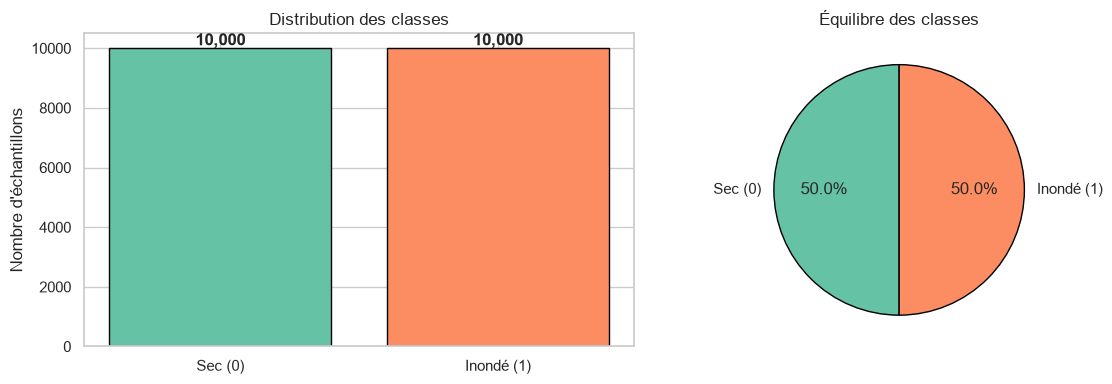

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar
counts = df["label"].value_counts().sort_index()
axes[0].bar(["Sec (0)", "Inondé (1)"], counts.values,
            color=["#66c2a5", "#fc8d62"], edgecolor="black")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 100, f"{v:,}", ha="center", fontweight="bold")
axes[0].set_title("Distribution des classes")
axes[0].set_ylabel("Nombre d'échantillons")

# Pie
axes[1].pie(counts.values, labels=["Sec (0)", "Inondé (1)"],
            autopct="%1.1f%%", colors=["#66c2a5", "#fc8d62"],
            startangle=90, wedgeprops=dict(edgecolor="black"))
axes[1].set_title("Équilibre des classes")

plt.tight_layout()
plt.show()

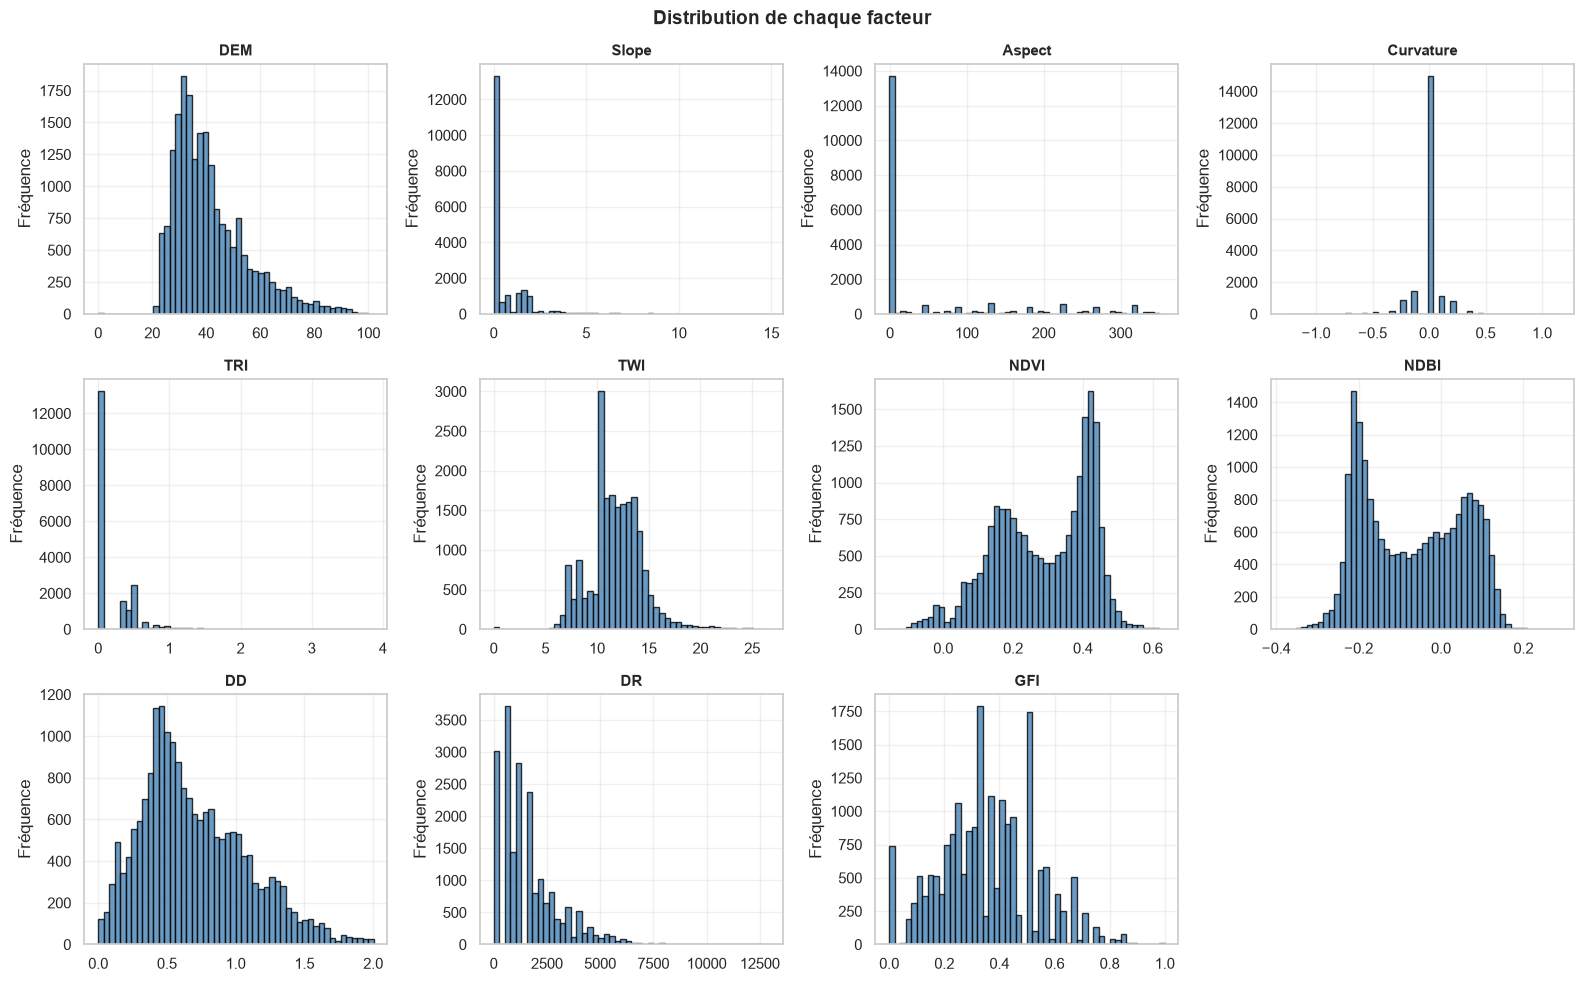

In [4]:
features = [c for c in df.columns if c != "label"]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].hist(df[col], bins=50, color="steelblue", edgecolor="black", alpha=0.8)
    axes[i].set_title(col, fontsize=11, fontweight="bold")
    axes[i].set_ylabel("Fréquence")
    axes[i].grid(alpha=0.3)

# Masquer les sous-graphes vides
for j in range(len(features), len(axes)):
    axes[j].axis("off")

plt.suptitle("Distribution de chaque facteur", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

C:\Users\Ghaith\AppData\Local\Temp\ipykernel_11904\1996316152.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=col, ax=axes[i],
C:\Users\Ghaith\AppData\Local\Temp\ipykernel_11904\1996316152.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=col, ax=axes[i],
C:\Users\Ghaith\AppData\Local\Temp\ipykernel_11904\1996316152.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="label", y=col, ax=axes[i],
C:\Users\Ghaith\AppData\Local\Temp\ipykernel_11904\1996316152.py:5: FutureWarning: 

Pas

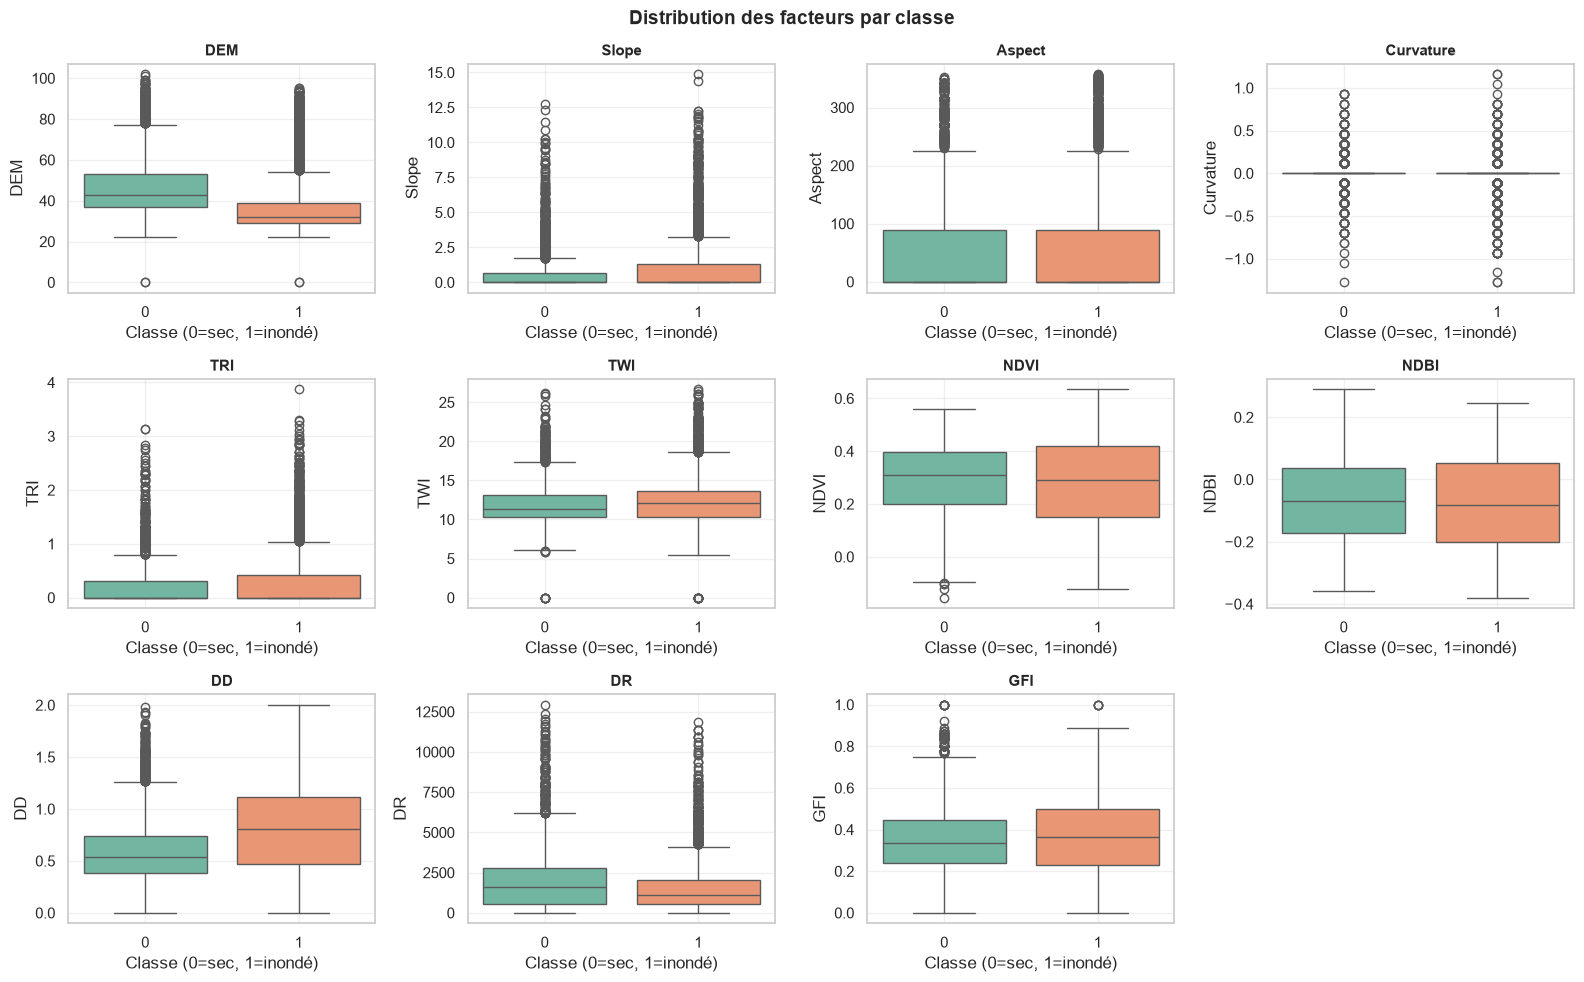

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(data=df, x="label", y=col, ax=axes[i],
                palette=["#66c2a5", "#fc8d62"])
    axes[i].set_title(col, fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Classe (0=sec, 1=inondé)")
    axes[i].grid(alpha=0.3)

for j in range(len(features), len(axes)):
    axes[j].axis("off")

plt.suptitle("Distribution des facteurs par classe", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

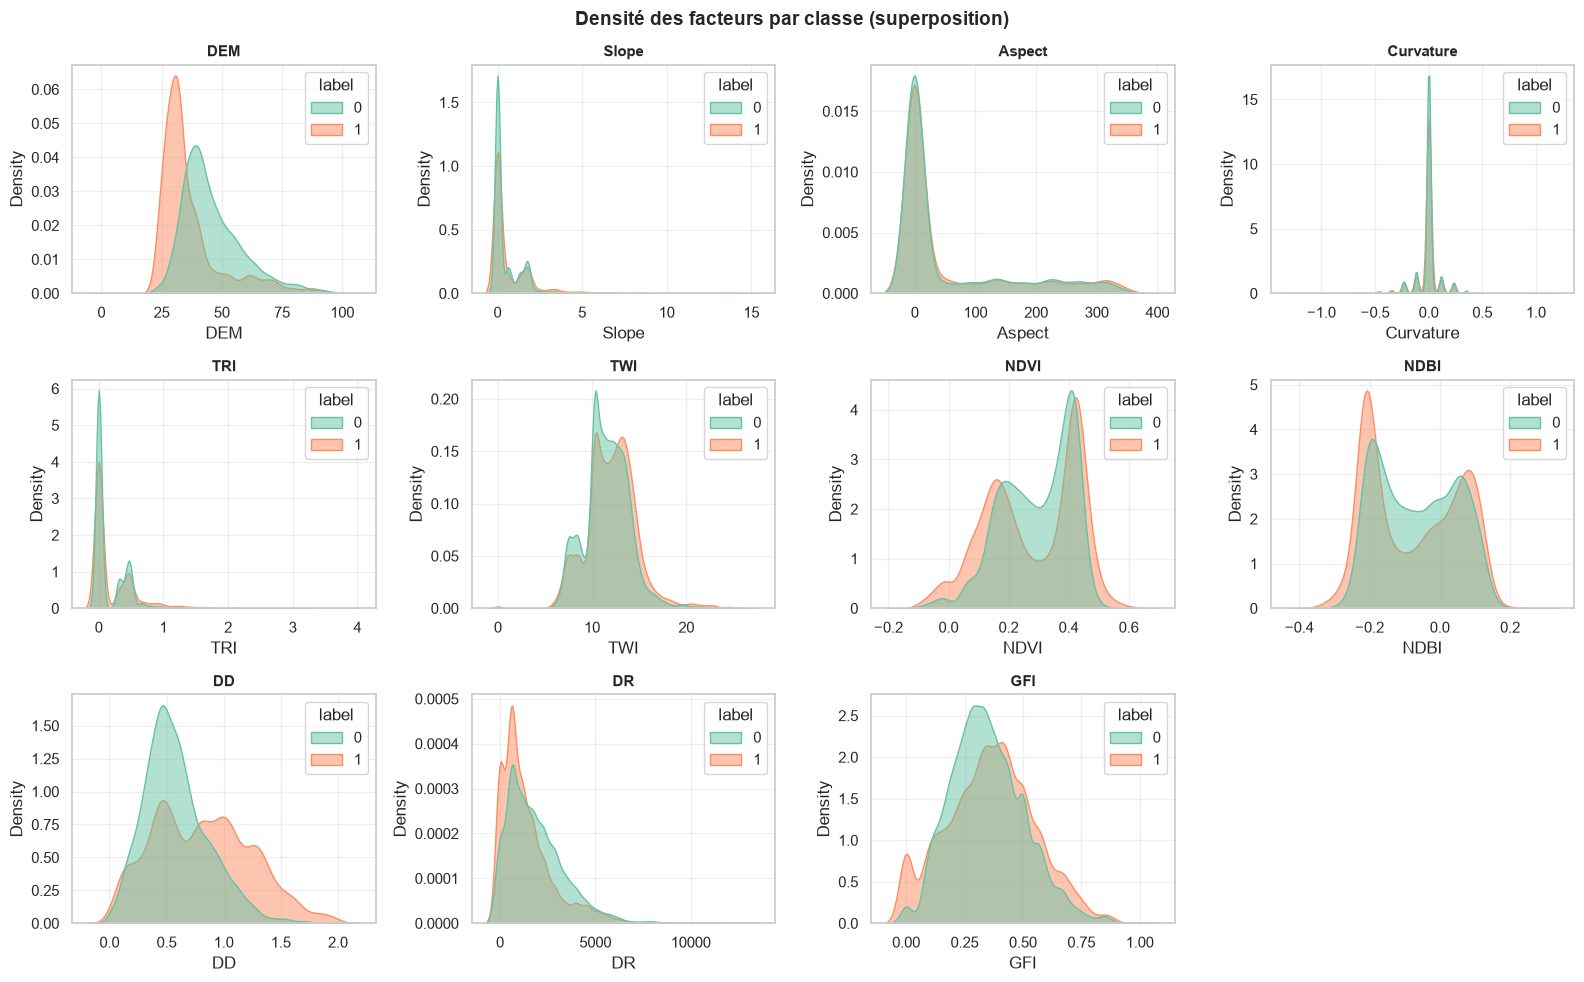

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.kdeplot(data=df, x=col, hue="label",
                fill=True, common_norm=False, alpha=0.5,
                palette=["#66c2a5", "#fc8d62"], ax=axes[i])
    axes[i].set_title(col, fontsize=11, fontweight="bold")
    axes[i].grid(alpha=0.3)

for j in range(len(features), len(axes)):
    axes[j].axis("off")

plt.suptitle("Densité des facteurs par classe (superposition)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

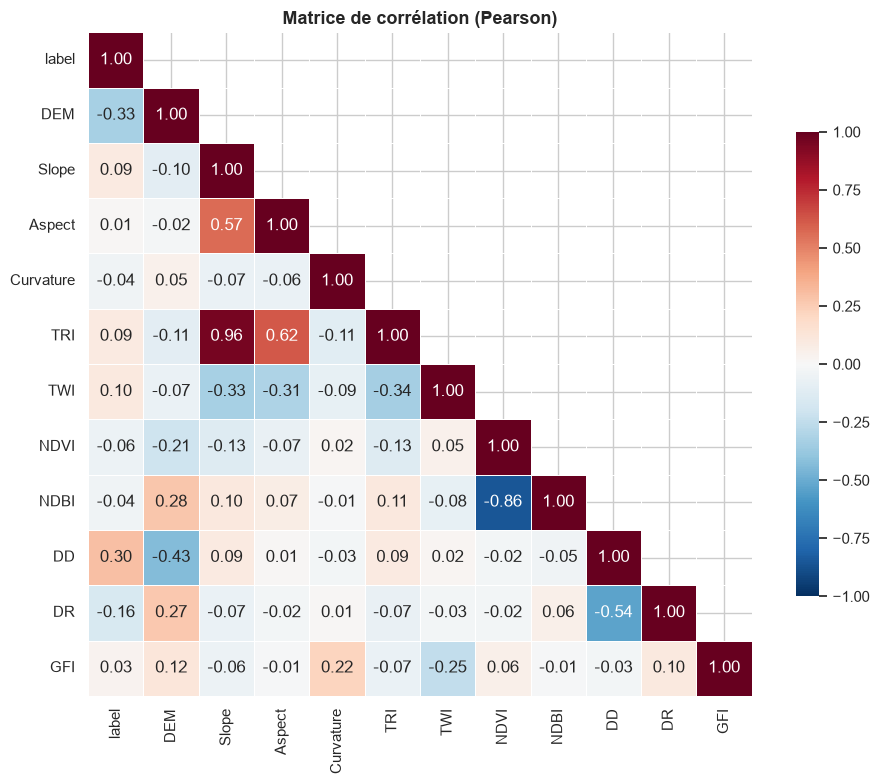


--- Paires de facteurs avec |corr| > 0.7 ---
  Slope      ↔ TRI        : +0.961
  NDVI       ↔ NDBI       : -0.856


In [7]:
plt.figure(figsize=(10, 8))
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.7})
plt.title("Matrice de corrélation (Pearson)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Afficher les paires fortement corrélées
print("\n--- Paires de facteurs avec |corr| > 0.7 ---")
corr_pairs = []
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        c = corr.iloc[i, j]
        if abs(c) > 0.7:
            corr_pairs.append((corr.columns[i], corr.columns[j], round(c, 3)))

if corr_pairs:
    for a, b, c in corr_pairs:
        print(f"  {a:10s} ↔ {b:10s} : {c:+.3f}")
else:
    print("  Aucune (bonne nouvelle pour le modèle !)")

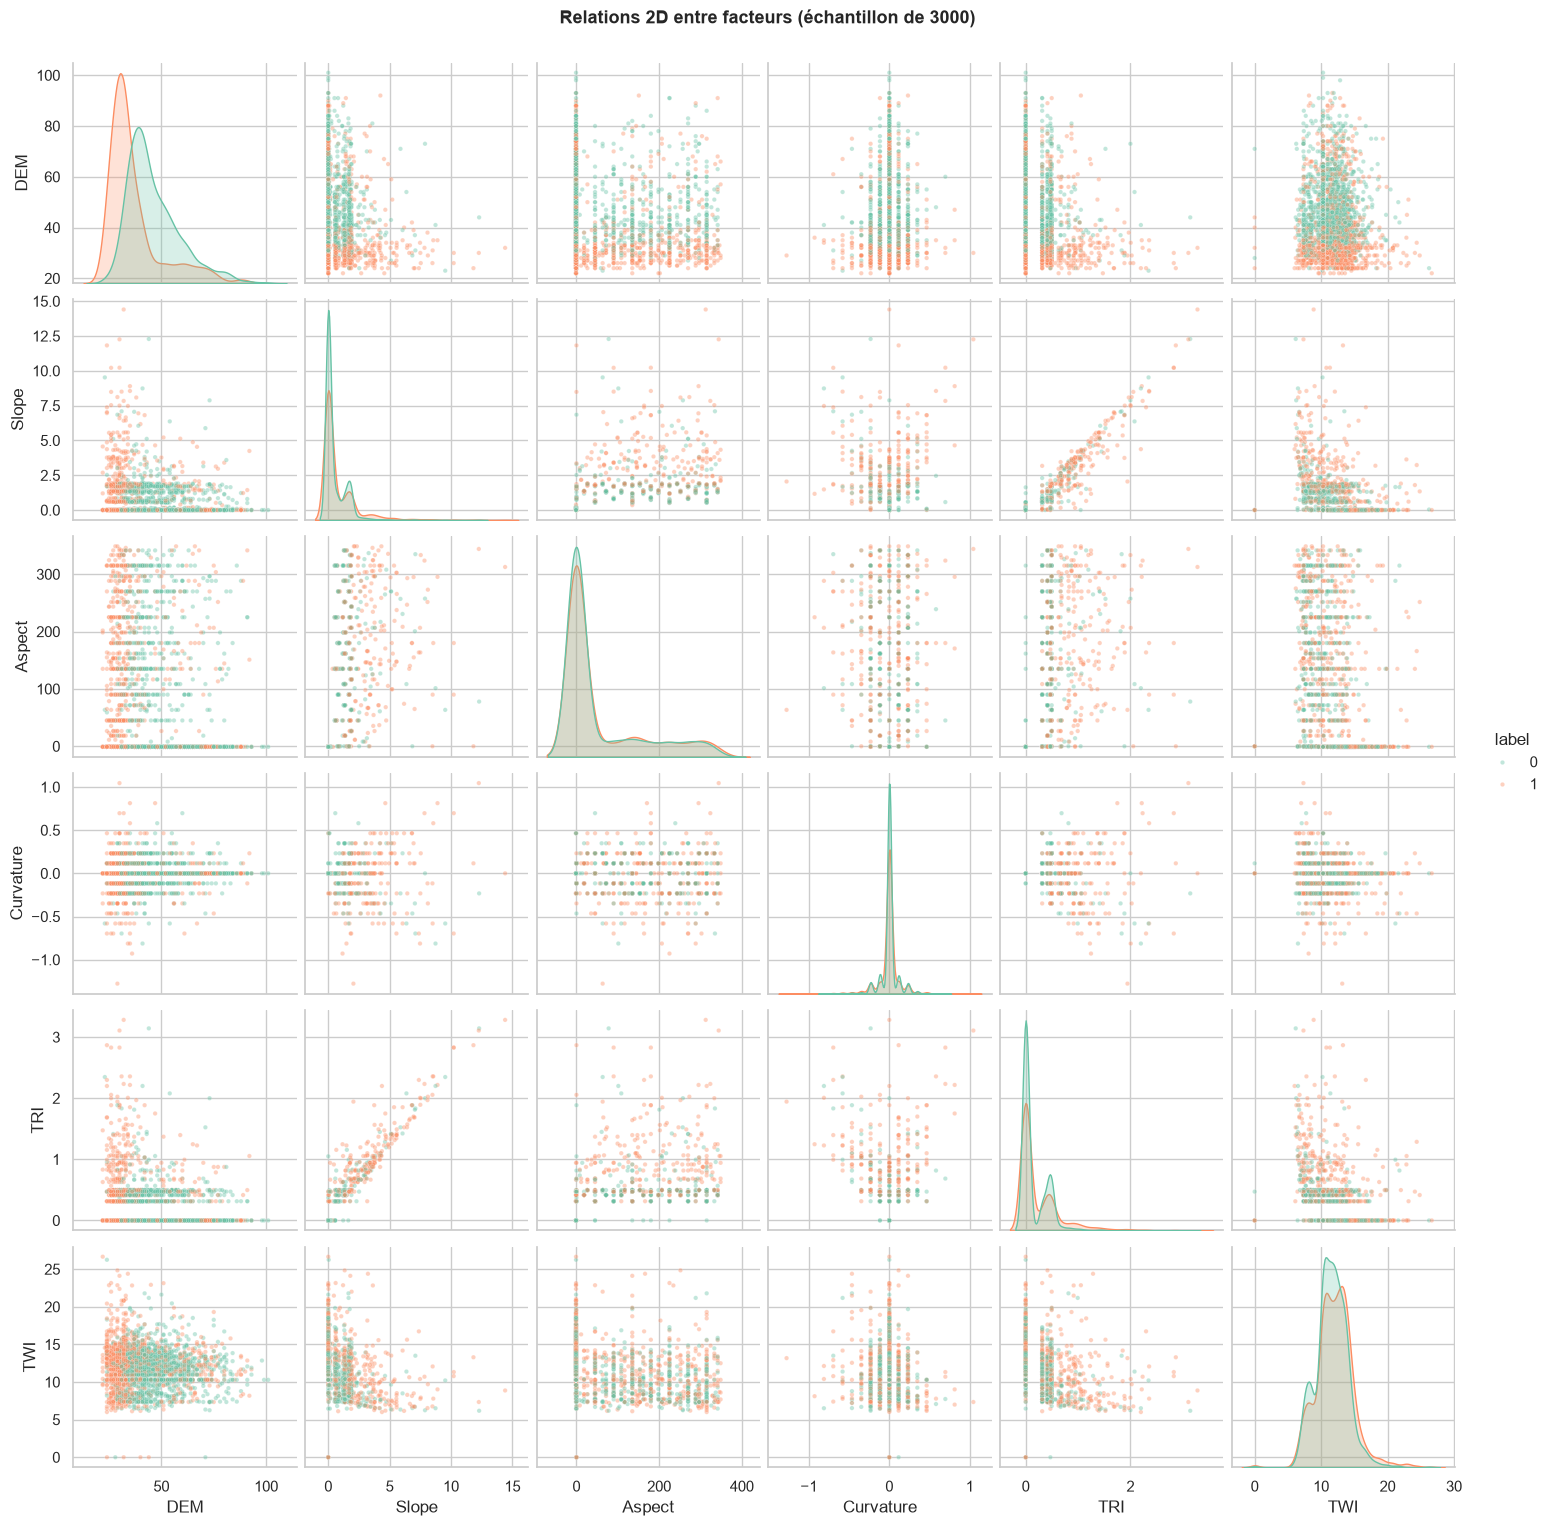

In [8]:
# Sur un échantillon pour ne pas surcharger
sample_df = df.sample(n=3000, random_state=42)

sns.pairplot(sample_df,
             vars=features[:6],     # 6 premiers facteurs pour lisibilité
             hue="label",
             palette=["#66c2a5", "#fc8d62"],
             diag_kind="kde",
             plot_kws={"alpha": 0.4, "s": 10})
plt.suptitle("Relations 2D entre facteurs (échantillon de 3000)", y=1.02, fontsize=13, fontweight="bold")
plt.show()

In [9]:
outlier_report = []
for col in features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_report.append({
        "feature": col,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "lower": round(lower, 2),
        "upper": round(upper, 2),
        "n_outliers": n_out,
        "pct": f"{100 * n_out / len(df):.1f}%",
    })

outlier_df = pd.DataFrame(outlier_report).sort_values("n_outliers", ascending=False)
display(outlier_df)

,feature,Q1,Q3,IQR,lower,upper,n_outliers,pct
3,Curvature,-0.00,0.00,0.00,-0.00,0.00,5015,25.1%
2,Aspect,-1.00,90.00,91.00,-137.50,226.50,1977,9.9%
1,Slope,0.00,0.85,0.85,-1.28,2.13,1277,6.4%
9,DR,562.13,2317.73,1755.60,-2071.27,4951.14,797,4.0%
0,DEM,32.00,48.00,16.00,8.00,72.00,789,3.9%
4,TRI,0.00,0.42,0.42,-0.62,1.04,625,3.1%
5,TWI,10.29,13.38,3.09,5.65,18.01,394,2.0%
8,DD,0.42,0.95,0.53,-0.38,1.75,196,1.0%
10,GFI,0.23,0.46,0.23,-0.12,0.81,154,0.8%
6,NDVI,0.17,0.41,0.23,-0.18,0.76,0,0.0%


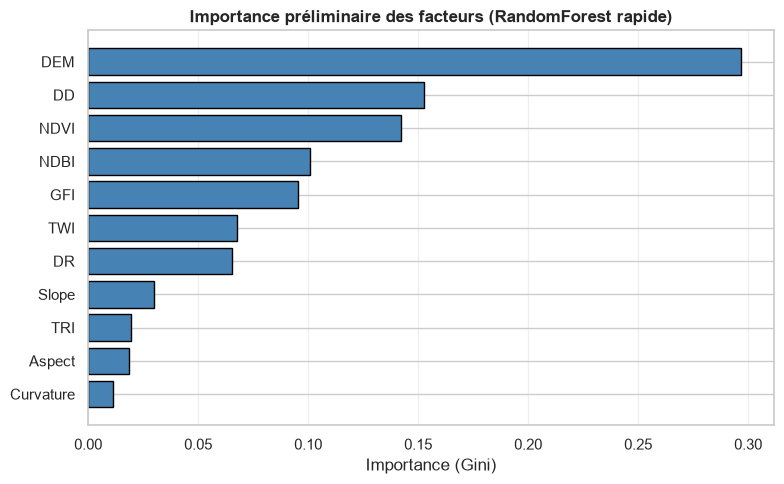

  feature  importance
      DEM    0.296904
       DD    0.152622
     NDVI    0.142331
     NDBI    0.100646
      GFI    0.095331
      TWI    0.067593
       DR    0.065160
    Slope    0.030124
      TRI    0.019685
   Aspect    0.018443
Curvature    0.011161


In [10]:
from sklearn.ensemble import RandomForestClassifier

X = df.drop("label", axis=1)
y = df["label"]

rf_quick = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_quick.fit(X, y)

imp = pd.DataFrame({
    "feature": X.columns,
    "importance": rf_quick.feature_importances_
}).sort_values("importance", ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(imp["feature"], imp["importance"],
         color="steelblue", edgecolor="black")
plt.xlabel("Importance (Gini)")
plt.title("Importance préliminaire des facteurs (RandomForest rapide)",
          fontsize=12, fontweight="bold")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print(imp.sort_values("importance", ascending=False).to_string(index=False))